### How does MAM temperature over the Nevadean Plateau affect JJA precipitation in Western North America?

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr

import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
import matplotlib.ticker as ticker

import geocat.viz as gv

from scipy.stats import ttest_ind

In [2]:
#file for coastlines
topo_file = xr.open_dataset("/home/mbucek/Miocene_Files/share/miocene_topo_pollard_antscape_dolan_0.5x0.5.nc",decode_times=False)

#main dataset
ds = xr.open_dataset("/groups/NBURLS/MioceneHydroProject/mbucek_files/hist/iF_MMIOx1_C5_840_B22WNA_FM23CA_icesm1.3.01_ALL_concat.nc",use_cftime=True)
ds

/tmp/ipykernel_2182572/2026914587.py:5: FutureWarning: Usage of 'use_cftime' as a kwarg is deprecated. Please pass a 'CFDatetimeCoder' instance initialized with 'use_cftime' to the 'decode_times' kwarg instead.
Example usage:
    time_coder = xr.coders.CFDatetimeCoder(use_cftime=True)
    ds = xr.open_dataset(decode_times=time_coder)

  ds = xr.open_dataset("/groups/NBURLS/MioceneHydroProject/mbucek_files/hist/iF_MMIOx1_C5_840_B22WNA_FM23CA_icesm1.3.01_ALL_concat.nc",use_cftime=True)


<xarray.Dataset> Size: 107GB
Dimensions:        (time: 193, lev: 30, ilev: 31, slat: 191, nbnd: 2, lat: 192,
                    lon: 288, slon: 288)
Coordinates:
  * time           (time) object 2kB 0001-02-01 00:00:00 ... 0017-02-01 00:00:00
  * lev            (lev) float64 240B 3.643 7.595 14.36 ... 957.5 976.3 992.6
  * ilev           (ilev) float64 248B 2.255 5.032 10.16 ... 967.5 985.1 1e+03
  * slat           (slat) float64 2kB -89.53 -88.59 -87.64 ... 87.64 88.59 89.53
  * lat            (lat) float64 2kB -90.0 -89.06 -88.12 ... 88.12 89.06 90.0
  * lon            (lon) float64 2kB 0.0 1.25 2.5 3.75 ... 356.2 357.5 358.8
  * slon           (slon) float64 2kB -0.625 0.625 1.875 ... 355.6 356.9 358.1
Dimensions without coordinates: nbnd
Data variables: (12/216)
    hyam           (time, lev) float64 46kB ...
    hybm           (time, lev) float64 46kB ...
    P0             (time) float64 2kB ...
    hyai           (time, ilev) float64 48kB ...
    hybi           (time, ilev) float64 48kB ...
    date           (time) int32 772B ...
    ...             ...
    pom_a1_SRF     (time, lat, lon) float32 43MB ...
    so4_a1_SRF     (time, lat, lon) float32 43MB ...
    so4_a2_SRF     (time, lat, lon) float32 43MB ...
    so4_a3_SRF     (time, lat, lon) float32 43MB ...
    soa_a1_SRF     (time, lat, lon) float32 43MB ...
    soa_a2_SRF     (time, lat, lon) float32 43MB ...
Attributes:
    Conventions:      CF-1.0
    source:           CAM
    case:             iF_MMIOx1_C5_840_B22WNA_FM23CA_icesm1.3.01
    title:            UNSET
    logname:          pacosta
    host:             derecho4
    Version:          $Name$
    revision_Id:      $Id$
    initial_file:     /glade/derecho/scratch/pacosta/iF.MMIOx1_C5_280_ECC0.01...
    topography_file:  /glade/work/pacosta/PaleoBC/acostar/REGRID/0.25_MMIO/PH...

In [3]:
#subset of dataset for Nevadean Plateau 
plateau = ds.sel(lat=slice(35,44), lon=slice(360-112, 360-102))
plateau_temp = plateau["T"].isel(lev=-1)
total_precip = ds["PRECC"] + ds["PRECL"]
#including precip just over the plateau in case it's needed for anything later
plateau_precip = plateau["PRECC"] + plateau["PRECL"]

#convert from K to degrees C
plateau_temp -= 273.15
#convert from m/s to mm/day
plateau_precip *= 86_400_000
total_precip *= 86_400_000

In [4]:
#calculate spatial average for each month
plateau_temp_avg = plateau_temp.mean(dim=["lat","lon"])
plateau_precip_avg = plateau_precip.mean(dim=["lat","lon"])
#precip_avg = total_precip.mean(dim=["lat","lon"])

In [5]:
#get temperature data for spring and precipitation data for summer 
grouped_temp = plateau_temp_avg.groupby("time.season")
grouped_precip = plateau_precip_avg.groupby("time.season") 
grouped_total_precip = total_precip.groupby("time.season")

#calculate average of season of interest for each of the 16 years
mam_temp = grouped_temp["MAM"].groupby("time.year").mean()
jja_plateau_precip = grouped_precip["JJA"].groupby("time.year").mean()
jja_precip = grouped_total_precip["JJA"].groupby("time.year").mean()

#calulate anomalies
temp_anom = mam_temp - mam_temp.mean(dim="year")
plateau_precip_anom = jja_plateau_precip - jja_plateau_precip.mean(dim="year")
precip_anom = jja_precip - jja_precip.mean(dim="year")

Text(0, 0.5, 'Temperature Anomaly (˚C)')

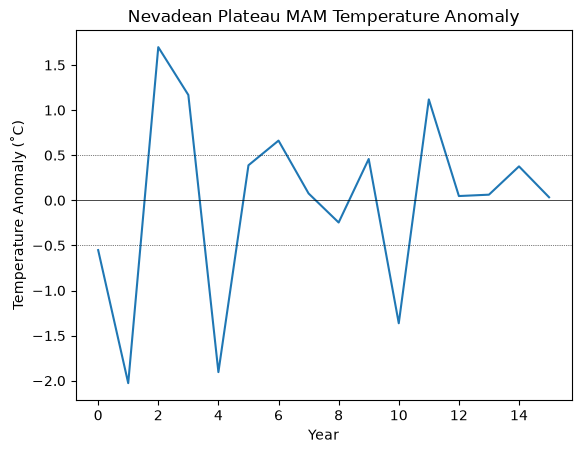

In [6]:
#plot of spring temperature anomaly by year 
plt.plot(temp_anom)
plt.axhline(0,color='black',linewidth=0.5)
plt.axhline(0.5,color='black',linewidth=0.5,linestyle='dotted')
plt.axhline(-0.5,color='black',linewidth=0.5,linestyle='dotted')
plt.title("Nevadean Plateau MAM Temperature Anomaly")
plt.xlabel("Year")
plt.ylabel("Temperature Anomaly (˚C)")

In [7]:
#create the composites 
warm_spring = precip_anom.where(temp_anom >= 0.5, drop=True)
cool_spring = precip_anom.where(temp_anom <= -0.5, drop=True)
neutral_spring = precip_anom.where(np.logical_and(temp_anom > -0.5, temp_anom < 0.5), drop=True)

#calculate average anomaly for each spring temperature condition 
warm_anom = warm_spring.mean(dim="year")
neutral_anom = neutral_spring.mean(dim="year")
cool_anom = cool_spring.mean(dim="year")

Text(0.59, 0.95, 'JJA Precipitation Anomalies in Response to\nMAM Temperature Anomalies Over\nthe Nevadean Plateau')

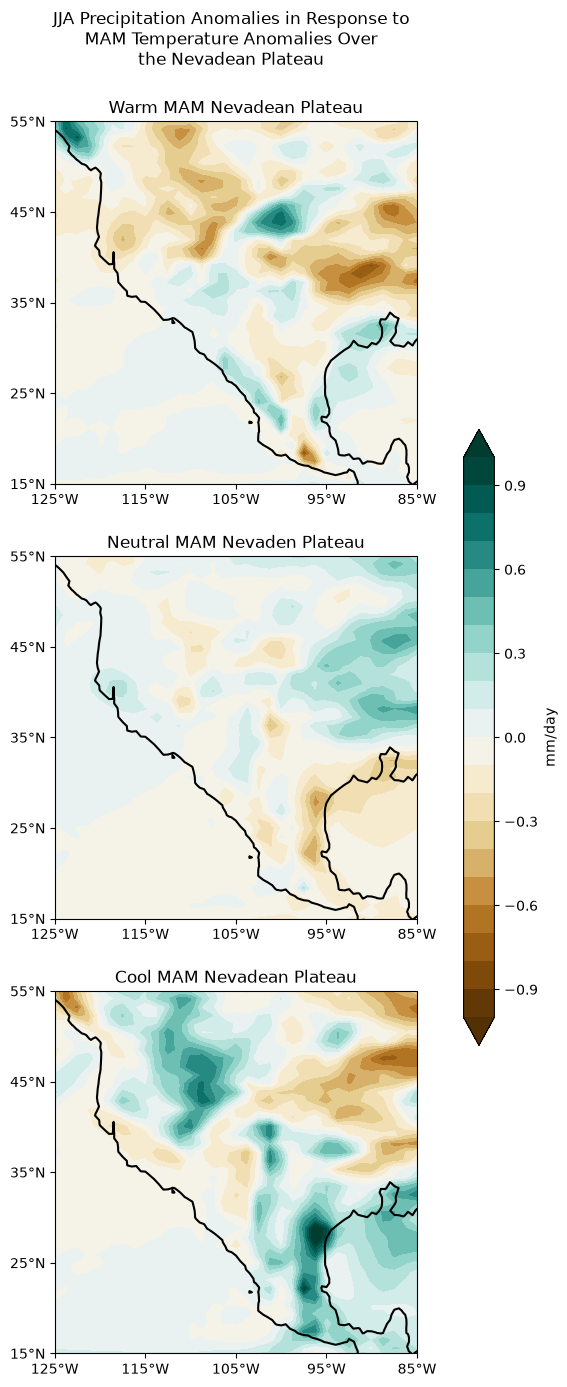

In [8]:
#plotting anomalies 

data = [warm_anom, neutral_anom, cool_anom] 

#setting up figure
fig, axs = plt.subplots(nrows=3, ncols=1, subplot_kw={'projection': ccrs.PlateCarree()}, figsize=(12,16))
axs = axs.flatten()

for i in range(len(data)):
    #using geocat to set up the plots because it's more straightforward
    gv.set_axes_limits_and_ticks(ax=axs[i],xlim=(-125, -85),ylim=(15, 55),xticks=np.linspace(-125, -85, 5),yticks=np.linspace(15, 55, 5))
    gv.add_lat_lon_ticklabels(axs[i])

    #plotting the data
    plot = axs[i].contourf(data[i].lon, data[i].lat, data[i], levels=np.linspace(-1,1,21), cmap="BrBG", extend="both")
    axs[i].contour(topo_file.lon, topo_file.lat, topo_file.topo, levels=[0], transform=ccrs.PlateCarree(), colors="k")

#colorbar
cbar = fig.colorbar(plot, ax=axs, orientation="vertical", shrink=0.5, label="mm/day")

#titles
axs[0].set_title("Warm MAM Nevadean Plateau")
axs[1].set_title("Neutral MAM Nevaden Plateau")
axs[2].set_title("Cool MAM Nevadean Plateau")
plt.suptitle("JJA Precipitation Anomalies in Response to\nMAM Temperature Anomalies Over\nthe Nevadean Plateau", x=0.59, y=0.95)

In [35]:
#defining variables needed for significance test
p = 0.05
diff_precip = [warm_anom-neutral_anom, cool_anom-neutral_anom]

Text(0.5, 0.98, 'Composite Precipitation Difference, Warm Spring - Neutral,\nWith Hatching Indicating Significance at p = 0.05')

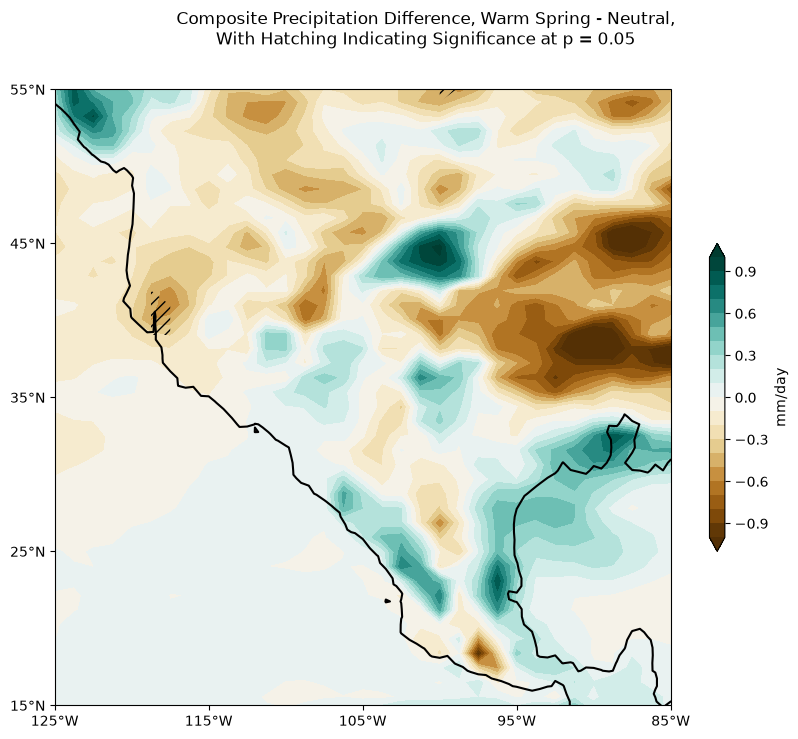

In [36]:
#t-test for warm spring precip significance 
tstat,pval = ttest_ind(warm_spring, neutral_spring, equal_var = False)

#mask where it is significant 
mask_diff = diff_precip[0].where(pval <= p)

data = [diff_precip[0]]

#setting up figure
fig, axs = plt.subplots(nrows=1, ncols=1, subplot_kw={'projection': ccrs.PlateCarree()}, figsize=(10,8), squeeze=False)
axs = axs.flatten()

for i in range(len(data)):
    #using geocat to set up the plots because it's more straightforward
    gv.set_axes_limits_and_ticks(ax=axs[i],xlim=(-125, -85),ylim=(15, 55),xticks=np.linspace(-125, -85, 5),yticks=np.linspace(15, 55, 5))
    gv.add_lat_lon_ticklabels(axs[i])

    #plotting the data
    plot = axs[i].contourf(data[i].lon, data[i].lat, data[i], levels=np.linspace(-1,1,21), cmap="BrBG", extend="both")
    axs[i].contour(topo_file.lon, topo_file.lat, topo_file.topo, levels=[0], transform=ccrs.PlateCarree(), colors="k")

    #significane hatching 
    hatching = axs[i].contourf(data[i].lon, data[i].lat, mask_diff, [0,1], transform=ccrs.PlateCarree(), colors=["none"], hatches=['///',''],extend='both')

#colorbar
cbar = fig.colorbar(plot, ax=axs, orientation="vertical", shrink=0.5, label="mm/day")

#titles
plt.suptitle("Composite Precipitation Difference, Warm Spring - Neutral,\nWith Hatching Indicating Significance at p = 0.05")

Text(0.5, 0.98, 'Composite Precipitation Difference, Cool Spring - Neutral,\nWith Hatching Indicating Significance at p = 0.05')

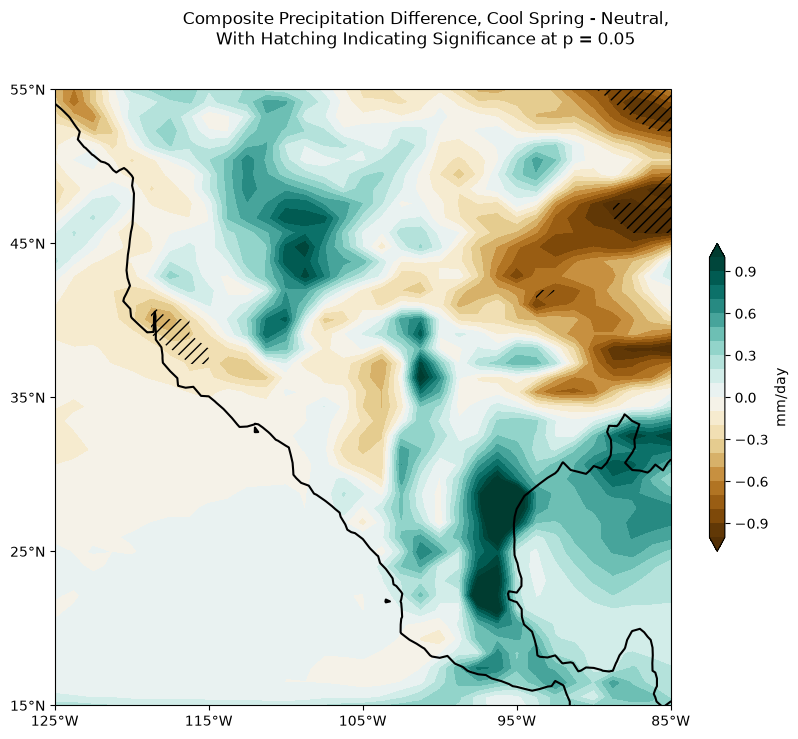

In [37]:
#t-test for cool spring precip significance
tstat,pval = ttest_ind(cool_spring, neutral_spring, equal_var = False)

#mask where it is significant 
mask_diff = diff_precip[1].where(pval <= p)

data = [diff_precip[1]]

#setting up figure
fig, axs = plt.subplots(nrows=1, ncols=1, subplot_kw={'projection': ccrs.PlateCarree()}, figsize=(10,8), squeeze=False)
axs = axs.flatten()

for i in range(len(data)):
    #using geocat to set up the plots because it's more straightforward
    gv.set_axes_limits_and_ticks(ax=axs[i],xlim=(-125, -85),ylim=(15, 55),xticks=np.linspace(-125, -85, 5),yticks=np.linspace(15, 55, 5))
    gv.add_lat_lon_ticklabels(axs[i])

    #plotting the data
    plot = axs[i].contourf(data[i].lon, data[i].lat, data[i], levels=np.linspace(-1,1,21), cmap="BrBG", extend="both")
    axs[i].contour(topo_file.lon, topo_file.lat, topo_file.topo, levels=[0], transform=ccrs.PlateCarree(), colors="k")

    #significane hatching 
    hatching = axs[i].contourf(data[i].lon, data[i].lat, mask_diff, [0,1], transform=ccrs.PlateCarree(), colors=["none"], hatches=['///',''],extend='both')

#colorbar
cbar = fig.colorbar(plot, ax=axs, orientation="vertical", shrink=0.5, label="mm/day")

#titles
plt.suptitle("Composite Precipitation Difference, Cool Spring - Neutral,\nWith Hatching Indicating Significance at p = 0.05")